In [1]:
from spp_extended_theory.Libs import libSPP
import pandas as pd

In [2]:
%cd "/home/thibault.derrien/Documents/spp-extended-theory/spp_extended_theory/SimpleSPP"

/home/thibault.derrien/Documents/spp-extended-theory/spp_extended_theory/SimpleSPP


In [3]:
# SPPdb = libSPP.GenerateDatabase()

In [4]:
db=pd.read_csv("SPPactiveInterfaces.dat", delimiter="\t", header=0, index_col=False)
# db = pd.DataFrame(SPPdb)
db=db.rename(columns={"#Material1": "Material1"})
db.describe(include="all")
db.dtypes

Material1               object
Material2               object
Wavelength             float64
OldSPPactiveBool        object
NewSPPactiveBool        object
SPPperiod              float64
SPPperiodError         float64
SPPdecayDepth1         float64
SPPdecayDepth2         float64
Reflectivity           float64
OpticalPenetration1    float64
OpticalPenetration2    float64
SPPdecayLength         float64
eps1real               float64
eps1imag               float64
eps2real               float64
eps2imag               float64
SPPdepthImagk1         float64
SPPdepthImagk2         float64
FaradayNumber          float64
JouleNumber            float64
dtype: object

In [5]:
db_init=db

In [6]:
db

,Material1,Material2,Wavelength,OldSPPactiveBool,NewSPPactiveBool,SPPperiod,SPPperiodError,SPPdecayDepth1,SPPdecayDepth2,Reflectivity,...,OpticalPenetration2,SPPdecayLength,eps1real,eps1imag,eps2real,eps2imag,SPPdepthImagk1,SPPdepthImagk2,FaradayNumber,JouleNumber
0,Air,Air,3200.0,No,No,4525.483400,226.274170,-1.000000e+09,-1.000000e+09,0.000000,...,-1.000000,-1.000000e+09,1.000000,0.000000,1.000000,0.000000,1.388401e+06,1.388401e+06,-1.000000e+09,1.000000
1,Air,Si (Palik),3200.0,No,No,3332.891237,154.724586,-1.000000e+09,-1.000000e+09,0.301378,...,-1.000000,-1.000000e+09,1.000000,0.000000,11.795007,0.000000,5.489207e+05,6.474524e+06,-1.000000e+09,0.014884
2,Air,"ZnO (Bond 1965, o)",3200.0,No,No,3614.137628,152.424998,-1.000000e+09,-1.000000e+09,0.097037,...,-1.000000,-1.000000e+09,1.000000,0.000000,3.628644,0.000000,9.126474e+05,3.311672e+06,-1.000000e+09,0.131998
3,Air,"ZnO (Bond 1965, e)",3200.0,No,No,3608.577717,152.355347,-1.000000e+09,-1.000000e+09,0.099061,...,-1.000000,-1.000000e+09,1.000000,0.000000,3.681026,0.000000,9.075266e+05,3.340629e+06,-1.000000e+09,0.128711
4,Air,Air,3100.0,No,No,4384.062043,219.203102,-1.000000e+09,-1.000000e+09,0.000000,...,-1.000000,-1.000000e+09,1.000000,0.000000,1.000000,0.000000,1.433188e+06,1.433188e+06,-1.000000e+09,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7118,Zr (Krishnan 1994),"TiO2 (Palik, o)",400.0,No,Yes,176.210919,2.721350,2.778234e+01,1.853646e+01,0.288162,...,269249.703593,1.931143e+01,-2.805962,7.180164,11.554154,0.000804,1.039413e+06,5.079449e+07,7.498171e+00,1.153290
7119,Zr (Krishnan 1994),V (Palik),400.0,No,No,299.144141,3.866008,4.179620e+01,1.796931e+01,0.043806,...,9.417452,1.675713e+01,-2.805962,7.180164,-4.917921,17.243273,-1.283039e+07,-3.415164e+07,6.672027e+00,0.282106
7120,Zr (Krishnan 1994),W (Palik),400.0,No,No,259.992233,2.769159,4.019864e+01,1.791340e+01,0.071579,...,13.207336,1.762628e+01,-2.805962,7.180164,5.682178,16.339516,-8.577055e+06,-4.867746e+07,6.999673e+00,0.321813
7121,Zr (Krishnan 1994),ZnO (Postava 2000),400.0,No,Yes,186.977555,3.797488,2.277949e+01,3.437966e+01,0.283782,...,1989.436789,4.114603e+01,-2.805962,7.180164,5.107344,0.072320,-1.125239e+07,2.371371e+07,1.745427e+01,4.927619


# Mixture of 1 material with other materials

In [7]:
wavelength=1030 #nm

In [8]:
db=db[db['Material1']=="Au (Palik)"]
db=db[db['Wavelength']==wavelength]

findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.


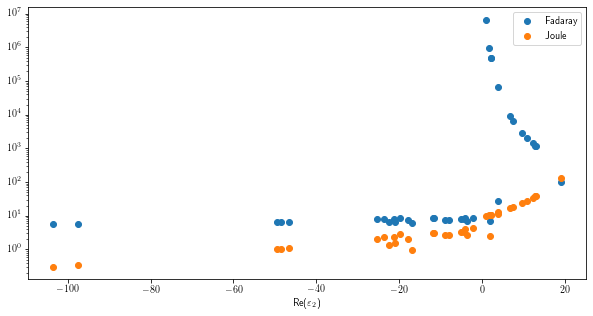

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.xlabel(r"Re($\varepsilon_2$)")
plt.semilogy(db.eps2real, db.FaradayNumber, "o", label="Fadaray")
plt.semilogy(db.eps2real, db.JouleNumber, "o", label="Joule")
plt.legend(loc="best")
plt.show()

In [10]:
from spp_extended_theory.Libs.libPlotting import makePlot
import numpy as np

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


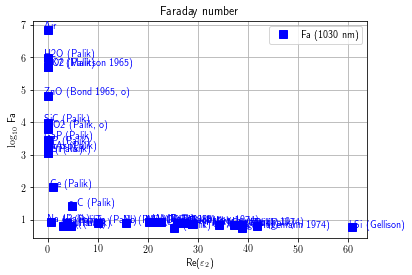

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


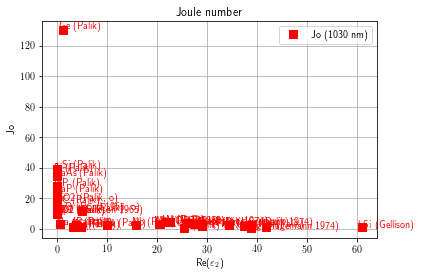

0

In [11]:

# def makePlot(x_data, y_data, tags, filename, plottitle, labelx, labely, functionlabel, textcolor)
makePlot(db.eps2imag, np.log10(db.FaradayNumber), db.Material2, "Faraday-Au-"+str(wavelength)+"nm.eps", "Faraday number", r"Re($\varepsilon_2$)", r"$\log_{10}$ Fa", "Fa ("+str(wavelength)+" nm)", "b")

makePlot(db.eps2imag, db.JouleNumber, db.Material2, "Joule-Au-"+str(wavelength)+"nm.eps", "Joule number", r"Re($\varepsilon_2$)", r"Jo", "Jo ("+str(wavelength)+" nm)", "r")